Specificity: Computes the Kalman filter on IV. It also does training on quotes and testing on trades. Results+evaluations plotted. 

In [1]:
import os
import sys
from datetime import date, datetime

# import torch
# from torch.func import jacrev
import jax
import jax.numpy as jnp
import matplotlib.pyplot as plt
import numpy as np
import plotly.express as px
import plotly.graph_objects as go
import polars as pl
import polars.selectors as cs
import pytz

project_root = os.path.abspath("/Users/elie/Documents/GitHub/quant_data/")

if project_root not in sys.path:
    sys.path.insert(0, project_root)


os.environ["QUANTDATA_RAW_DATA"] = "!/quantdata/raw"  # better set these to environment variables
os.environ["QUANTDATA_TRAINING_DATA"] = (
    "!/quantdata/training"  # better set these to environment variables
)
os.environ["QUANTDATA_PROCESSING_DATA"] = (
    "!/quantdata/processing"  # better set these to environment variables
)
os.environ["QUANTDATA_CACHE_MODE"] = "on"  # turns off global cache mode
os.environ["QUANTDATA_TEST_MODE"] = "0"
import importlib as imp

import quantdata as _

imp.reload(_)
import quantdata.biz_calendar as _

imp.reload(_)
import quantdata.massive.client as _

imp.reload(_)
import quantdata.massive.options.contracts as _

imp.reload(_)

from datetime import date

sys.path.insert(
    0, os.path.join(os.path.dirname(os.path.abspath("__file__")), "..", "shared_functions")
)


import arbitrage
import black_scholes
import ekf
import events
from cdxcore.util import fmt_date, fmt_dict
from cdxcore.verbose import Context

import personal.shared_functions.kalman_filters as kalman_filters
import personal.shared_functions.plots as plots
import personal.shared_functions.utils as utils
from personal.shared_functions.iv_evaluation import evaluate_kalman_iv
from quantdata.massive.client import MassiveClient
from quantdata.massive.taq import TAQMatchConfig, match_taq

/Users/elie/Documents/GitHub/quant_data/quantdata/__init__.py:212: UserWarning: Using cache mode 'on' as specified in environment variable QUANTDATA_CACHE_MODE.


In [2]:
df_tickers = pl.read_csv("../spy_options_tickers.csv")

In [3]:
trade_date = date(2024, 1, 3)
client = MassiveClient()
df_spy = client.fetch_trades("SPY", trade_date)

In [45]:
# Single call — processes all calls and puts in one batched IV computation.
# is_call column in the output distinguishes the two types.
df_quote_result, df_trade_result = kalman_filters.build_iv_surface(
    df_tickers=df_tickers,
    trade_date=trade_date,
    df_spy=df_spy,
    min_trades=100,
    simple=False,
    # discount_factor_clip=(0.0, 2.0),
)

O:SPY240105C00469000: dropping 2 bad quotes (crossed×2 (first=2024-01-03 11:49:45.633413-05:00))
O:SPY240105C00472000: dropping 1 bad quotes (crossed×1 (first=2024-01-03 15:51:02.275318-05:00))
O:SPY240105C00473000: dropping 1 bad quotes (crossed×1 (first=2024-01-03 10:29:17.744517-05:00))
O:SPY240105C00474000: dropping 4 bad quotes (crossed×4 (first=2024-01-03 10:25:56.925706-05:00))
O:SPY240105C00475000: dropping 1 bad quotes (crossed×1 (first=2024-01-03 14:02:06.496803-05:00))
O:SPY240105C00477000: dropping 1 bad quotes (crossed×1 (first=2024-01-03 10:00:44.569057-05:00))
O:SPY240105C00481000: dropping 46 bad quotes (sub-tick bid×46 (first=2024-01-03 16:00:02.443177-05:00))
O:SPY240105C00482000: dropping 64 bad quotes (sub-tick bid×64 (first=2024-01-03 10:00:01.421753-05:00))
O:SPY240105C00483000: dropping 842 bad quotes (sub-tick bid×842 (first=2024-01-03 09:30:00.060278-05:00), zero bid size×1 (first=2024-01-03 09:30:00.060278-05:00))
O:SPY240105C00484000: dropping 2129 bad quotes

In [46]:
df_spy

ts_ns,price,size,trade_code
"datetime[ns, America/New_York]",f64,f64,u32
2024-01-03 04:00:00.023728896 EST,472.04,4.0,73728
2024-01-03 04:00:00.033502208 EST,472.43,16.0,73728
2024-01-03 04:00:00.035570944 EST,472.36,1.0,73728
2024-01-03 04:00:00.035577088 EST,472.31,4.0,73728
2024-01-03 04:00:00.370607616 EST,472.16,2.0,73728
…,…,…,…
2024-01-03 19:59:57.242399488 EST,469.35,100.0,8192
2024-01-03 19:59:57.242399488 EST,469.35,400.0,8192
2024-01-03 19:59:58.998797568 EST,469.355,1.0,73728


In [47]:
df_quote_result

ts_ns,observed_iv,bid_iv,ask_iv,kalman_iv,bid_price,ask_price,forward,discount_factor,kalman_price,strike,is_call
"datetime[ns, America/New_York]",f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,bool
2024-01-03 09:30:00.006736128 EST,0.140982,0.138439,0.143359,0.140982,0.04,0.05,470.43,null,0.045034,481.0,true
2024-01-03 09:30:00.006781440 EST,0.13695,0.134075,0.139497,0.13695,0.09,0.11,470.43,null,0.100363,479.0,true
2024-01-03 09:30:00.007484160 EST,0.143359,0.132705,0.15164,0.143354,0.03,0.07,470.43,null,0.050011,481.0,true
2024-01-03 09:30:00.008294144 EST,0.127732,0.126371,0.129092,0.127732,2.17,2.21,470.43,null,2.189967,471.0,false
2024-01-03 09:30:00.008340992 EST,0.138195,0.131123,0.144509,0.138193,0.08,0.13,470.43,null,0.105011,479.0,true
…,…,…,…,…,…,…,…,…,…,…,…
2024-01-03 16:14:59.881741568 EST,0.134535,0.134132,0.134856,0.134535,1.88,1.89,469.055,1.0,1.885548,469.0,true
2024-01-03 16:14:59.884593152 EST,0.138451,0.132675,0.144803,0.138453,5.28,5.38,469.055,1.0,5.326722,474.0,false
2024-01-03 16:14:59.884598272 EST,0.13324,0.131454,0.136743,0.133241,3.66,3.72,469.055,1.0,3.680191,472.0,false


shape: (9, 2)
┌────────────┬────────────┐
│ statistic  ┆ value      │
│ ---        ┆ ---        │
│ str        ┆ f64        │
╞════════════╪════════════╡
│ count      ┆ 2.193119e6 │
│ null_count ┆ 50.0       │
│ mean       ┆ 1.000192   │
│ std        ┆ 0.001662   │
│ min        ┆ 0.998      │
│ 25%        ┆ 0.998      │
│ 50%        ┆ 1.0        │
│ 75%        ┆ 1.002      │
│ max        ┆ 1.002      │
└────────────┴────────────┘
0
50


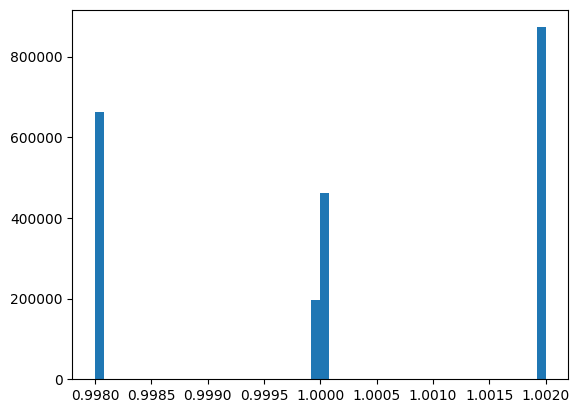

In [48]:
# forward/discount factor checks
print(df_quote_result["discount_factor"].describe())
plt.hist(df_quote_result["discount_factor"], bins=50)
print(df_quote_result["forward"].is_null().sum())
print(df_quote_result["discount_factor"].is_null().sum())

In [49]:
df_trade_result

ts_ns,observed_iv,bid_iv,ask_iv,bid_price,ask_price,kalman_matched,trade_residual,kalman_price,strike,is_call
"datetime[ns, America/New_York]",f64,f64,f64,f64,f64,f64,f64,f64,f64,bool
2024-01-03 09:30:00.031 EST,0.130745,0.130745,0.1441,0.08,0.13,0.13765,-0.006905,0.104434,479.0,true
2024-01-03 09:30:00.051 EST,0.142976,0.139489,0.142976,0.07,0.08,0.139871,0.003105,0.071086,480.0,true
2024-01-03 09:30:00.059 EST,0.153329,0.01,0.1651,0.0,0.05,null,null,NaN,483.0,true
2024-01-03 09:30:00.102 EST,0.154323,0.149303,0.151009,0.22,0.23,0.150466,0.003857,0.226927,463.0,false
2024-01-03 09:30:00.102 EST,0.141628,0.141628,0.143618,0.57,0.59,0.141883,-0.000255,0.572613,466.0,false
…,…,…,…,…,…,…,…,…,…,…
2024-01-03 16:14:55.650 EST,0.137266,0.136469,0.137266,1.03,1.04,0.136871,0.000395,1.035049,467.0,false
2024-01-03 16:14:56.139 EST,0.13631,0.134822,0.13631,1.38,1.4,0.135455,0.000855,1.388353,468.0,false
2024-01-03 16:14:56.139 EST,0.13631,0.134822,0.13631,1.38,1.4,0.135455,0.000855,1.388353,468.0,false


In [50]:
df_trade_result = df_trade_result.filter(
    pl.all_horizontal(pl.all().is_not_null()) & pl.all_horizontal(cs.float().is_not_nan())
)
print(f"{df_trade_result.shape[0]:,} rows with no nulls / NaNs out of {df_trade_result.shape[0]:,}")

74,410 rows with no nulls / NaNs out of 74,410


In [51]:
df_trade_result.select(
    pl.col("trade_residual") ** 2
).mean() * 100000  # multiplicator just for better readability of the number

trade_residual
f64
0.719106


## Quptes smile

In [52]:
import personal.shared_functions.utils as _u

df_iv_surface_long = df_quote_result
df_iv_surface_wide = utils.synchronize_iv_surface(df_iv_surface_long)
df_filtered = df_iv_surface_wide.filter(
    pl.all_horizontal(pl.all().is_not_null()) & pl.all_horizontal(cs.float().is_not_nan())
)

strikes_all = sorted(df_iv_surface_long["strike"].unique().to_list())
strikes_C = sorted(df_iv_surface_long.filter(pl.col("is_call"))["strike"].unique().to_list())
strikes_P = sorted(df_iv_surface_long.filter(~pl.col("is_call"))["strike"].unique().to_list())

_, expiry, _ = _u.parse_option_ticker(
    df_tickers.filter(pl.col("ticker").str.contains("C"))["ticker"][0]
)

row_idx = df_filtered.shape[0] // 2  # ← change this (0 to df_filtered.shape[0]-1)
snapshot_ts = df_filtered["ts_ns"][row_idx]
row = df_iv_surface_wide.filter(pl.col("ts_ns") <= snapshot_ts).tail(1)

fig = go.Figure()

fig.add_trace(
    go.Scatter(
        x=strikes_C,
        y=[row[f"kalman_iv_{int(k)}_C"][0] for k in strikes_C],
        mode="lines+markers",
        name="calls — kalman mid",
        line=dict(color="royalblue"),
    )
)
fig.add_trace(
    go.Scatter(
        x=strikes_C,
        y=[row[f"bid_iv_{int(k)}_C"][0] for k in strikes_C],
        mode="lines",
        name="calls — bid",
        line=dict(color="royalblue", dash="dot"),
    )
)
fig.add_trace(
    go.Scatter(
        x=strikes_C,
        y=[row[f"ask_iv_{int(k)}_C"][0] for k in strikes_C],
        mode="lines",
        name="calls — ask",
        line=dict(color="royalblue", dash="dot"),
    )
)

fig.add_trace(
    go.Scatter(
        x=strikes_P,
        y=[row[f"kalman_iv_{int(k)}_P"][0] for k in strikes_P],
        mode="lines+markers",
        name="puts — kalman mid",
        line=dict(color="firebrick"),
    )
)
fig.add_trace(
    go.Scatter(
        x=strikes_P,
        y=[row[f"bid_iv_{int(k)}_P"][0] for k in strikes_P],
        mode="lines",
        name="puts — bid",
        line=dict(color="firebrick", dash="dot"),
    )
)
fig.add_trace(
    go.Scatter(
        x=strikes_P,
        y=[row[f"ask_iv_{int(k)}_P"][0] for k in strikes_P],
        mode="lines",
        name="puts — ask",
        line=dict(color="firebrick", dash="dot"),
    )
)

fig.update_layout(
    title=f"IV smile (calls + puts) — {snapshot_ts}",
    xaxis_title="Strike",
    yaxis_title="Implied Vol",
)
fig.show()

In [53]:
row

ts_ns,bid_iv_450_P,ask_iv_450_P,kalman_iv_450_P,bid_iv_454_C,ask_iv_454_C,kalman_iv_454_C,bid_iv_458_P,ask_iv_458_P,kalman_iv_458_P,bid_iv_459_P,ask_iv_459_P,kalman_iv_459_P,bid_iv_460_P,ask_iv_460_P,kalman_iv_460_P,bid_iv_461_P,ask_iv_461_P,kalman_iv_461_P,bid_iv_462_P,ask_iv_462_P,kalman_iv_462_P,bid_iv_462_P_right,ask_iv_462_P_right,kalman_iv_462_P_right,bid_iv_463_P,ask_iv_463_P,kalman_iv_463_P,bid_iv_464_P,ask_iv_464_P,kalman_iv_464_P,bid_iv_465_P,ask_iv_465_P,kalman_iv_465_P,bid_iv_465_C,ask_iv_465_C,kalman_iv_465_C,…,bid_iv_475_C,ask_iv_475_C,kalman_iv_475_C,bid_iv_476_P,ask_iv_476_P,kalman_iv_476_P,bid_iv_476_C,ask_iv_476_C,kalman_iv_476_C,bid_iv_477_P,ask_iv_477_P,kalman_iv_477_P,bid_iv_477_C,ask_iv_477_C,kalman_iv_477_C,bid_iv_478_C,ask_iv_478_C,kalman_iv_478_C,bid_iv_479_C,ask_iv_479_C,kalman_iv_479_C,bid_iv_480_C,ask_iv_480_C,kalman_iv_480_C,bid_iv_481_C,ask_iv_481_C,kalman_iv_481_C,bid_iv_482_C,ask_iv_482_C,kalman_iv_482_C,bid_iv_483_C,ask_iv_483_C,kalman_iv_483_C,bid_iv_484_C,ask_iv_484_C,kalman_iv_484_C,forward
"datetime[ns, America/New_York]",f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,…,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64
2024-01-03 12:56:18.293149440 EST,0.236685,0.248672,0.243413,0.01,0.273549,0.17395,0.172201,0.177247,0.174344,0.165424,0.169757,0.167362,0.159988,0.1634,0.161179,0.154205,0.157111,0.155385,0.150253,0.152563,0.151383,0.147723,0.149808,0.148966,0.146179,0.14804,0.147548,0.143969,0.145458,0.144839,0.142397,0.1436,0.142837,0.137843,0.147514,0.142756,…,0.132017,0.133138,0.132612,0.138542,0.152268,0.145592,0.132377,0.133786,0.133254,0.149283,0.165851,0.15787,0.132924,0.134727,0.133696,0.132762,0.135278,0.134581,0.13416,0.137444,0.136379,0.138252,0.14253,0.140345,0.138569,0.144538,0.142302,0.141504,0.149702,0.146736,0.157122,0.166098,0.159207,0.149233,0.157785,0.151116,470.32


In [54]:
spy_mid = df_spy.filter(pl.col("ts_ns") <= snapshot_ts)["price"][-1]

otm_strikes = sorted(set(strikes_C) | set(strikes_P))
otm_mid, otm_bid, otm_ask = [], [], []

for k in otm_strikes:
    K_int = int(k)
    has_C = f"kalman_iv_{K_int}_C" in row.columns
    has_P = f"kalman_iv_{K_int}_P" in row.columns

    bid_C = row[f"bid_iv_{K_int}_C"][0] if has_C else None
    ask_C = row[f"ask_iv_{K_int}_C"][0] if has_C else None
    bid_P = row[f"bid_iv_{K_int}_P"][0] if has_P else None
    ask_P = row[f"ask_iv_{K_int}_P"][0] if has_P else None

    if has_C and has_P and None not in (bid_C, ask_C, bid_P, ask_P):
        i_bid = max(bid_C, bid_P)
        i_ask = min(ask_C, ask_P)
        if i_bid <= i_ask:
            # spreads overlap → use intersection
            otm_bid.append(i_bid)
            otm_ask.append(i_ask)
            otm_mid.append((i_bid + i_ask) / 2)
        else:
            # no overlap → use OTM leg
            if k > spy_mid:
                otm_bid.append(bid_C)
                otm_ask.append(ask_C)
                otm_mid.append(row[f"kalman_iv_{K_int}_C"][0])
            else:
                otm_bid.append(bid_P)
                otm_ask.append(ask_P)
                otm_mid.append(row[f"kalman_iv_{K_int}_P"][0])
    elif has_C and None not in (bid_C, ask_C):
        otm_bid.append(bid_C)
        otm_ask.append(ask_C)
        otm_mid.append(row[f"kalman_iv_{K_int}_C"][0])
    elif has_P and None not in (bid_P, ask_P):
        otm_bid.append(bid_P)
        otm_ask.append(ask_P)
        otm_mid.append(row[f"kalman_iv_{K_int}_P"][0])
    else:
        otm_bid.append(None)
        otm_ask.append(None)
        otm_mid.append(None)

fig = go.Figure()
fig.add_trace(go.Scatter(x=otm_strikes, y=otm_mid, mode="lines+markers", name="OTM kalman mid"))
fig.add_trace(
    go.Scatter(x=otm_strikes, y=otm_bid, mode="lines", name="OTM bid", line=dict(dash="dot"))
)
fig.add_trace(
    go.Scatter(x=otm_strikes, y=otm_ask, mode="lines", name="OTM ask", line=dict(dash="dot"))
)
fig.add_vline(x=spy_mid, line_dash="dash", line_color="gray", annotation_text=f"SPY={spy_mid:.2f}")
fig.update_layout(
    title=f"OTM IV smile — {snapshot_ts}",
    xaxis_title="Strike",
    yaxis_title="Implied Vol",
)
fig.show()

In [55]:
tte = float((expiry - snapshot_ts).total_seconds()) / (365.25 * 24 * 3600)

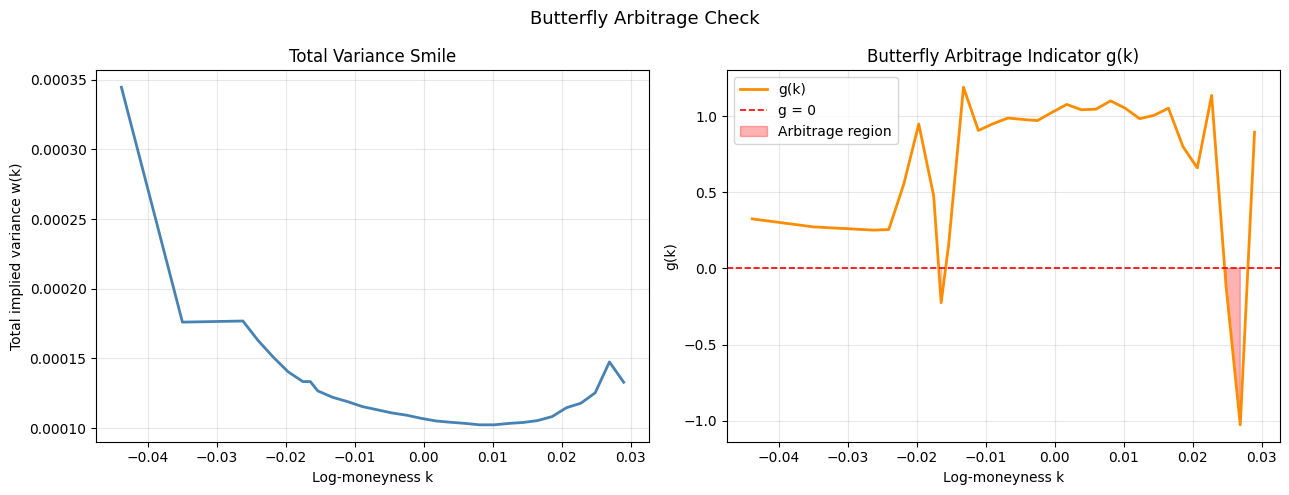

{'is_arbitrage_free': False,
 'min_g': -1.0267720840401826,
 'violations': array([-0.01646342,  0.02483414,  0.02690668]),
 'g': array([ 0.32507391,  0.27248258,  0.25121718,  0.25516777,  0.55328239,
         0.94707244,  0.47572289, -0.22497083,  0.15336929,  1.18919049,
         0.90524601,  0.94976825,  0.98685607,  0.9777021 ,  0.9700648 ,
         1.02443478,  1.07630018,  1.04124665,  1.0450523 ,  1.09942778,
         1.05188307,  0.98248628,  1.00488726,  1.0511653 ,  0.79985657,
         0.65928456,  1.13566969, -0.11100435, -1.02677208,  0.893842  ]),
 'w': array([0.00034468, 0.00017603, 0.00017682, 0.00016295, 0.00015113,
        0.00014046, 0.00013332, 0.00013332, 0.00012665, 0.00012204,
        0.00011896, 0.00011539, 0.00011311, 0.00011083, 0.00010921,
        0.00010693, 0.00010506, 0.00010412, 0.00010332, 0.00010228,
        0.0001023 , 0.0001033 , 0.00010398, 0.00010536, 0.0001082 ,
        0.00011458, 0.0001178 , 0.00012526, 0.00014745, 0.00013284]),
 'k': array([-0.0

In [56]:
log_moneyness_strikes = np.log(np.array(otm_strikes) / df_quote_result["forward"][row_idx])

arbitrage.check_butterfly(log_moneyness_strikes, otm_mid, T=tte, plot=True)

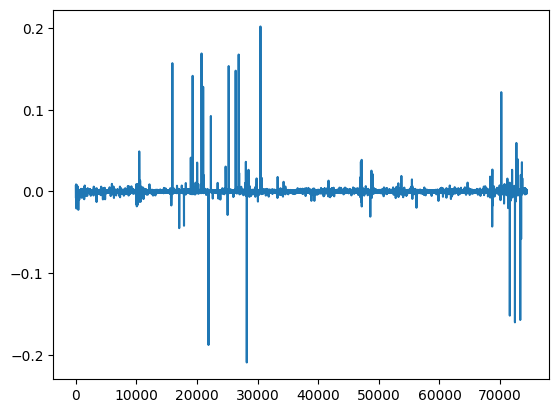

In [57]:
plt.plot(df_trade_result["trade_residual"])

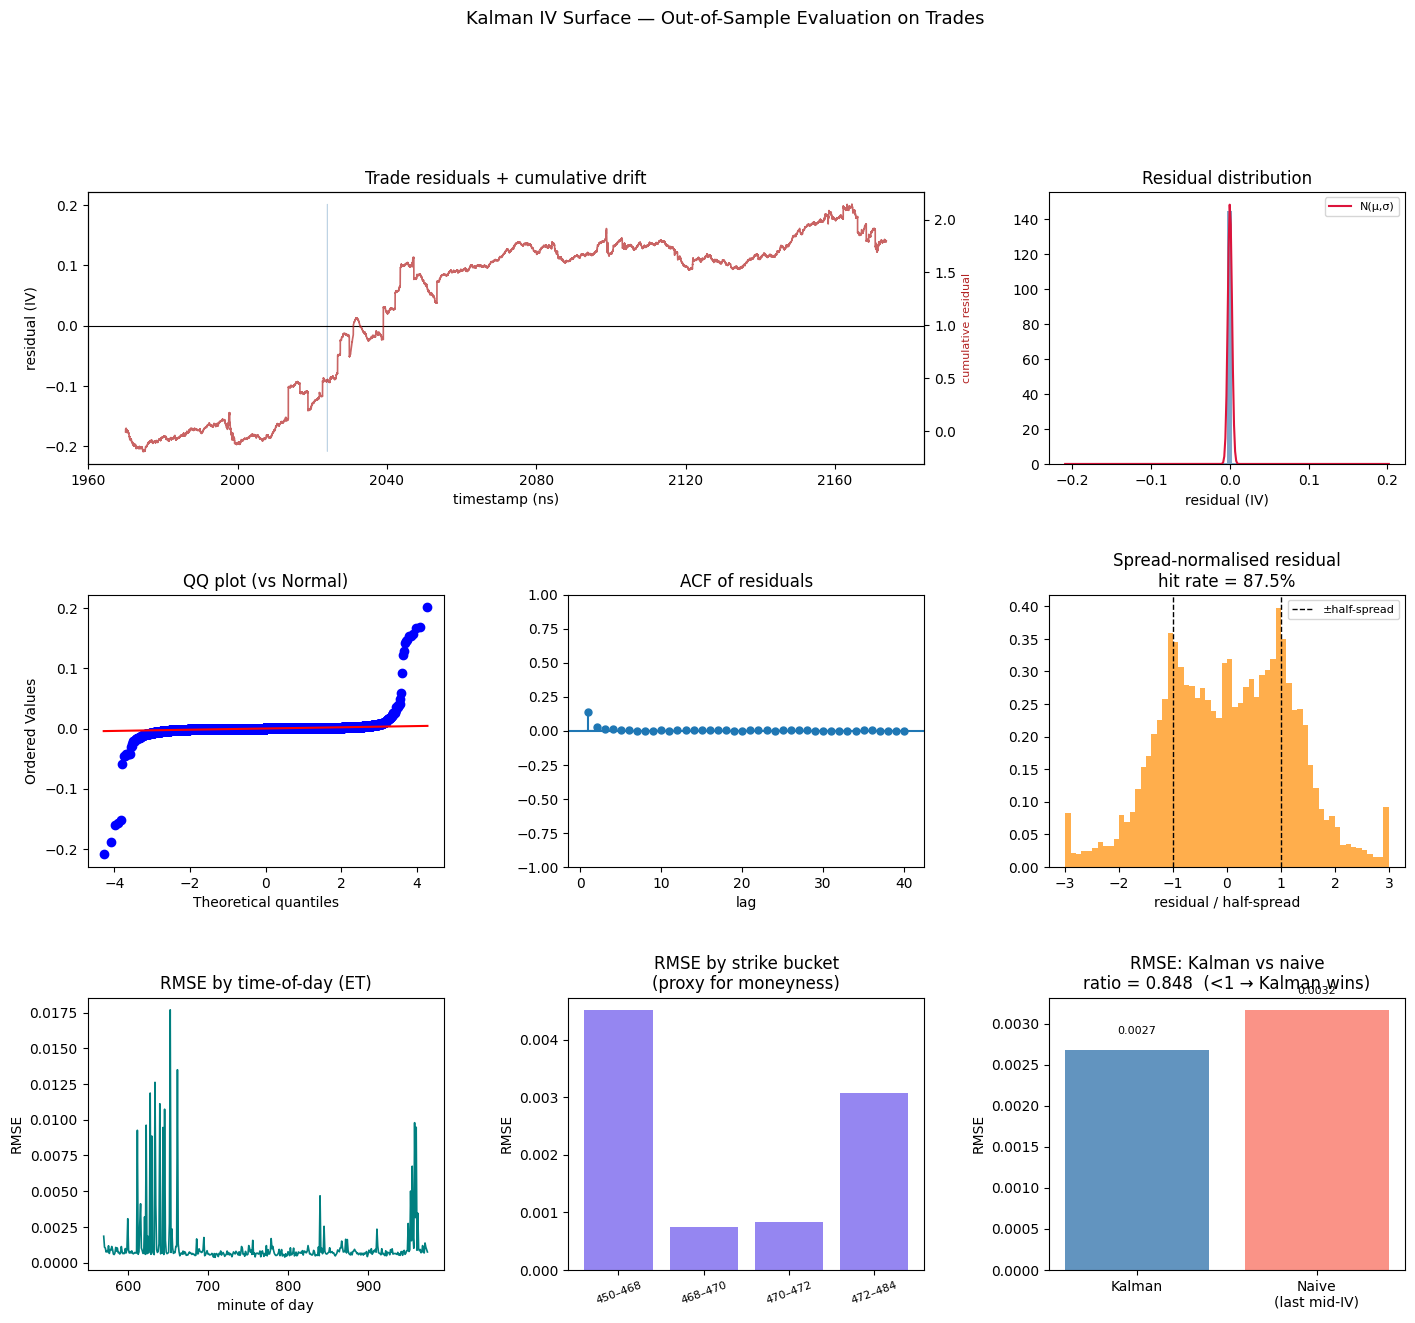

RMSE                 0.00268
MAE                  0.00063
Bias                 0.00002
Hit rate             87.5%
Naive RMSE           0.00316
RMSE ratio           0.848  (<1 = Kalman beats naive)

Ljung-Box (H0: no autocorrelation in residuals):
        lb_stat      lb_pvalue
10  1436.993121  1.020510e-302
20  1447.974398  5.749029e-295


In [58]:
metrics = evaluate_kalman_iv(df_quote_result, df_trade_result)

## Price Viz

In [59]:
df_price_surface_wide = utils.synchronize_price_surface(
    df_quote_result.rename({"kalman_price": "observed_price"})
)

In [60]:
df_filtered_price = df_price_surface_wide.filter(
    pl.all_horizontal(pl.all().is_not_null()) & pl.all_horizontal(cs.float().is_not_nan())
)
df_price_surface_long = df_quote_result.rename({"kalman_price": "observed_price"})

strikes_all = sorted(df_price_surface_long["strike"].unique().to_list())
strikes_C = sorted(df_price_surface_long.filter(pl.col("is_call"))["strike"].unique().to_list())
strikes_P = sorted(df_price_surface_long.filter(~pl.col("is_call"))["strike"].unique().to_list())

_, expiry, _ = _u.parse_option_ticker(
    df_tickers.filter(pl.col("ticker").str.contains("C"))["ticker"][0]
)

row_idx = df_filtered_price.shape[0] // 2  # ← change this (0 to df_filtered.shape[0]-1)
snapshot_ts = df_filtered_price["ts_ns"][row_idx]
row = df_price_surface_wide.filter(pl.col("ts_ns") <= snapshot_ts).tail(1)

fig = go.Figure()

fig.add_trace(
    go.Scatter(
        x=strikes_C,
        y=[row[f"observed_price_{int(k)}_C"][0] for k in strikes_C],
        mode="lines+markers",
        name="calls — kalman mid",
        line=dict(color="royalblue"),
    )
)
fig.add_trace(
    go.Scatter(
        x=strikes_C,
        y=[row[f"bid_price_{int(k)}_C"][0] for k in strikes_C],
        mode="lines",
        name="calls — bid",
        line=dict(color="royalblue", dash="dot"),
    )
)
fig.add_trace(
    go.Scatter(
        x=strikes_C,
        y=[row[f"ask_price_{int(k)}_C"][0] for k in strikes_C],
        mode="lines",
        name="calls — ask",
        line=dict(color="royalblue", dash="dot"),
    )
)

fig.add_trace(
    go.Scatter(
        x=strikes_P,
        y=[row[f"observed_price_{int(k)}_P"][0] for k in strikes_P],
        mode="lines+markers",
        name="puts — kalman mid",
        line=dict(color="firebrick"),
    )
)
fig.add_trace(
    go.Scatter(
        x=strikes_P,
        y=[row[f"bid_price_{int(k)}_P"][0] for k in strikes_P],
        mode="lines",
        name="puts — bid",
        line=dict(color="firebrick", dash="dot"),
    )
)
fig.add_trace(
    go.Scatter(
        x=strikes_P,
        y=[row[f"ask_price_{int(k)}_P"][0] for k in strikes_P],
        mode="lines",
        name="puts — ask",
        line=dict(color="firebrick", dash="dot"),
    )
)

fig.update_layout(
    title=f"price smile (calls + puts) — {snapshot_ts}",
    xaxis_title="Strike",
    yaxis_title="Implied Vol",
)
fig.show()

## MASS

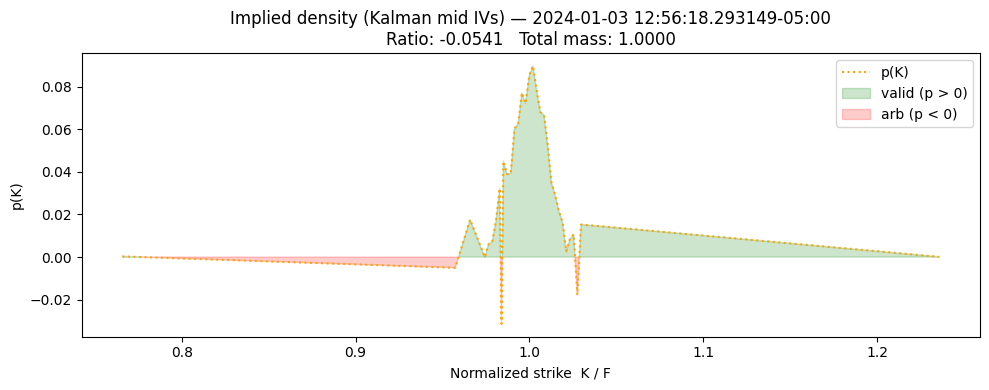

-0.054108196688374376 1.0


In [61]:
# ── Implied probability density from Kalman IVs (Breeden-Litzenberger) ──────
# Depends on: snapshot_ts, expiry, spy_mid, otm_strikes, otm_mid
import scipy.stats as stats


def _bs_call(F, K, T, sigma):
    """Black-Scholes call price with r=0 (forward = spot)."""
    if sigma <= 0 or T <= 0:
        return float(max(F - K, 0.0))
    d1 = (np.log(F / K) + 0.5 * sigma**2 * T) / (sigma * np.sqrt(T))
    d2 = d1 - sigma * np.sqrt(T)
    return float(F * stats.norm.cdf(d1) - K * stats.norm.cdf(d2))


F = spy_mid  # forward ≈ spot (r=0)
tte = float((expiry - snapshot_ts).total_seconds()) / (365.25 * 24 * 3600)

# Filter strikes with a valid Kalman mid IV
valid = [(k, iv) for k, iv in zip(otm_strikes, otm_mid) if iv is not None]
strikes = np.array([v[0] for v in valid])
ivs = np.array([v[1] for v in valid])

# Normalize to pure space: kappa = K/F, C_pure = C_BS / F
pure_strikes = strikes / F
pure_mids = np.array([_bs_call(F, k, tte, iv) / F for k, iv in zip(strikes, ivs)])

# Extend strike grid with boundary conditions
strikesx = np.zeros(len(pure_strikes) + 2)
strikesx[1:-1] = pure_strikes
strikesx[0] = pure_strikes[0] * 0.8  # far left (deep ITM)
strikesx[-1] = pure_strikes[-1] * 1.2  # far right (deep OTM)

midx = np.zeros_like(strikesx)
midx[1:-1] = pure_mids
midx[0] = 1.0 - strikesx[0]  # deep ITM call ≈ F - K → 1 - kappa
midx[-1] = 0.0  # deep OTM call → 0

# Breeden-Litzenberger: d²C/dK² = risk-neutral density
dCdK = np.diff(midx, prepend=1.0) / np.diff(strikesx, prepend=0.0)
p = np.diff(dCdK, append=0.0)

# Correct approach: compute dC/dK directly, no phantom prepend
dCdK = np.diff(midx) / np.diff(strikesx)

# Left boundary slope = -1 (deep ITM call slope)
# Right boundary slope = 0 (deep OTM call slope)
dCdK_full = np.concatenate([[-1.0], dCdK, [0.0]])

# Second derivative = density
p = np.diff(dCdK_full)


ratio = np.sum(p[p < 0.0])  # negative mass = butterfly arbitrage
total = np.sum(p)  # should be ≈ 1

fig, ax = plt.subplots(figsize=(10, 4))
ax.set_title(
    f"Implied density (Kalman mid IVs) — {snapshot_ts}\nRatio: {ratio:.4f}   Total mass: {total:.4f}"
)
ax.set_xlabel("Normalized strike  K / F")
ax.set_ylabel("p(K)")
ax.plot(strikesx, p, ":", color="orange", label="p(K)")
ax.fill_between(
    strikesx,
    0,
    p,
    where=(p >= 0),
    interpolate=True,
    color="green",
    alpha=0.2,
    label="valid (p > 0)",
)
ax.fill_between(
    strikesx, p, 0, where=(p < 0), interpolate=True, color="red", alpha=0.2, label="arb (p < 0)"
)
# ax.axhline(0, color="purple", linestyle=":")
# ax.axvline(1.0, color="gray", linestyle="--", alpha=0.5, label="ATM (K=F)")
ax.legend()
plt.tight_layout()
plt.show()

print(ratio, total)

In [62]:
print("strikesx:", strikesx[:5], "...", strikesx[-3:])
print("midx:    ", midx[:5], "...", midx[-3:])
print("dCdK_full:", dCdK_full[:5], "...", dCdK_full[-3:])
print("p:        ", p[:5], "...", p[-3:])
print("ratio:", ratio, "total:", total)

strikesx: [0.76591671 0.95739588 0.96590607 0.97441625 0.9765438 ] ... [1.02760491 1.02973246 1.23567895]
midx:     [0.23408329 0.04266235 0.03411215 0.02571138 0.02361103] ... [5.32632773e-05 2.05621863e-05 0.00000000e+00]
dCdK_full: [-1.         -0.9996959  -1.00470125 -0.98714285 -0.98721659] ... [-1.53703303e-02 -9.98423722e-05  0.00000000e+00]
p:         [ 3.04102321e-04 -5.00534861e-03  1.75583956e-02 -7.37429603e-05
  6.03973686e-03] ... [-1.77120971e-02  1.52704879e-02  9.98423722e-05]
ratio: -0.054108196688374376 total: 1.0


In [63]:
print("strikes:", strikes_C[:8])
print("mids:   ", [round(x, 5) for x in midx[:8]])

# Check monotonicity explicitly
for i in range(1, len(midx)):
    if midx[i] >= midx[i - 1]:
        print(
            f"NON-MONOTONE at index {i}: "
            f"C({strikesx[i - 1]})={midx[i - 1]:.5f} "
            f">= C({strikesx[i]})={midx[i]:.5f}"
        )

strikes: [454.0, 465.0, 466.0, 467.0, 468.0, 469.0, 470.0, 471.0]
mids:    [np.float64(0.23408), np.float64(0.04266), np.float64(0.03411), np.float64(0.02571), np.float64(0.02361), np.float64(0.02152), np.float64(0.01945), np.float64(0.01742)]
NON-MONOTONE at index 29: C(1.0254773682250944)=0.00005 >= C(1.0276049146322004)=0.00005


In [64]:
df_iv_surface_long = df_quote_result
df_iv_surface_wide = utils.synchronize_iv_surface(df_iv_surface_long)
df_filtered = df_iv_surface_wide.filter(
    pl.all_horizontal(pl.all().is_not_null()) & pl.all_horizontal(cs.float().is_not_nan())
)

strikes_all = sorted(df_iv_surface_long["strike"].unique().to_list())
strikes_C = sorted(df_iv_surface_long.filter(pl.col("is_call"))["strike"].unique().to_list())
strikes_P = sorted(df_iv_surface_long.filter(~pl.col("is_call"))["strike"].unique().to_list())

_, expiry, _ = _u.parse_option_ticker(
    df_tickers.filter(pl.col("ticker").str.contains("C"))["ticker"][0]
)

row_idx = df_filtered.shape[0] // 2  # ← change this (0 to df_filtered.shape[0]-1)
snapshot_ts = df_filtered["ts_ns"][row_idx]
row = df_iv_surface_wide.filter(pl.col("ts_ns") <= snapshot_ts).tail(1)

In [65]:
def extract_otm_details(row_idx, df_filtered, strikes_C, strikes_P):
    snapshot_ts = df_filtered["ts_ns"][row_idx]
    row = df_iv_surface_wide.filter(pl.col("ts_ns") <= snapshot_ts).tail(1)
    spy_mid = df_spy.filter(pl.col("ts_ns") <= snapshot_ts)["price"][-1]

    otm_strikes = sorted(set(strikes_C) | set(strikes_P))
    otm_mid, otm_bid, otm_ask = [], [], []

    for k in otm_strikes:
        K_int = int(k)
        has_C = f"kalman_iv_{K_int}_C" in row.columns
        has_P = f"kalman_iv_{K_int}_P" in row.columns

        bid_C = row[f"bid_iv_{K_int}_C"][0] if has_C else None
        ask_C = row[f"ask_iv_{K_int}_C"][0] if has_C else None
        bid_P = row[f"bid_iv_{K_int}_P"][0] if has_P else None
        ask_P = row[f"ask_iv_{K_int}_P"][0] if has_P else None

        if has_C and has_P and None not in (bid_C, ask_C, bid_P, ask_P):
            i_bid = max(bid_C, bid_P)
            i_ask = min(ask_C, ask_P)
            if i_bid <= i_ask:
                # spreads overlap → use intersection
                otm_bid.append(i_bid)
                otm_ask.append(i_ask)
                otm_mid.append((i_bid + i_ask) / 2)
            else:
                # no overlap → use OTM leg
                if k > spy_mid:
                    otm_bid.append(bid_C)
                    otm_ask.append(ask_C)
                    otm_mid.append(row[f"kalman_iv_{K_int}_C"][0])
                else:
                    otm_bid.append(bid_P)
                    otm_ask.append(ask_P)
                    otm_mid.append(row[f"kalman_iv_{K_int}_P"][0])
        elif has_C and None not in (bid_C, ask_C):
            otm_bid.append(bid_C)
            otm_ask.append(ask_C)
            otm_mid.append(row[f"kalman_iv_{K_int}_C"][0])
        elif has_P and None not in (bid_P, ask_P):
            otm_bid.append(bid_P)
            otm_ask.append(ask_P)
            otm_mid.append(row[f"kalman_iv_{K_int}_P"][0])
        else:
            otm_bid.append(None)
            otm_ask.append(None)
            otm_mid.append(None)
    return otm_strikes, otm_mid, otm_bid, otm_ask

In [66]:
def is_arbitrage_row_idx(row_idx, df_filtered, expiry):
    row = df_filtered[row_idx]
    tte = float((expiry - row["ts_ns"])[0].total_seconds()) / (365.25 * 24 * 3600)
    mid_ivs_C = [row[f"kalman_iv_{int(k)}_C"][0] for k in strikes_C]
    return arbitrage.check_butterfly(k=strikes_C, iv=mid_ivs_C, T=tte, plot=False)

In [67]:
def compute_negative_mass_idx(row_idx, df_filtered, df_spy, expiry, otm_strikes, otm_mid):
    snapshot_ts = df_filtered["ts_ns"][row_idx]
    # F = spy_mid because forward ≈ spot (r=0)
    F = df_spy.filter(pl.col("ts_ns") <= snapshot_ts)["price"][-1]

    tte = float((expiry - snapshot_ts).total_seconds()) / (365.25 * 24 * 3600)

    # Filter strikes with a valid Kalman mid IV
    valid = [(k, iv) for k, iv in zip(otm_strikes, otm_mid) if iv is not None]
    strikes = np.array([v[0] for v in valid])
    ivs = np.array([v[1] for v in valid])

    # Normalize to pure space: kappa = K/F, C_pure = C_BS / F
    pure_strikes = strikes / F
    pure_mids = np.array([_bs_call(F, k, tte, iv) / F for k, iv in zip(strikes, ivs)])

    # Extend strike grid with boundary conditions
    strikesx = np.zeros(len(pure_strikes) + 2)
    strikesx[1:-1] = pure_strikes
    strikesx[0] = pure_strikes[0] * 0.8  # far left (deep ITM)
    strikesx[-1] = pure_strikes[-1] * 1.2  # far right (deep OTM)

    midx = np.zeros_like(strikesx)
    midx[1:-1] = pure_mids
    midx[0] = 1.0 - strikesx[0]  # deep ITM call ≈ F - K → 1 - kappa
    midx[-1] = 0.0  # deep OTM call → 0

    # Correct approach: compute dC/dK directly, no phantom prepend
    dCdK = np.diff(midx) / np.diff(strikesx)

    # Left boundary slope = -1 (deep ITM call slope)
    # Right boundary slope = 0 (deep OTM call slope)
    dCdK_full = np.concatenate([[-1.0], dCdK, [0.0]])

    # Second derivative = density
    p = np.diff(dCdK_full)

    # Breeden-Litzenberger: d²C/dK² = risk-neutral density
    # dCdK = np.diff(midx, prepend=1.0) / np.diff(strikesx, prepend=0.0)
    # p = np.diff(dCdK, append=0.0)

    ratio = np.sum(p[p < 0.0])  # negative mass = butterfly arbitrage
    total = np.sum(p)  # should be ≈ 1
    result = {
        "is_arbitrage_free": ratio >= 0.0,
        "negative_mass_ratio": ratio,
        "total_mass": total,
        "density": (strikesx, p),
    }
    return result

In [68]:
res = []
for i in range(0, df_filtered.shape[0], 100000):
    otm_strikes, otm_mid, otm_bid, otm_ask = extract_otm_details(
        i, df_filtered, strikes_C, strikes_P
    )
    result = compute_negative_mass_idx(i, df_filtered, df_spy, expiry, otm_strikes, otm_mid)
    res.append(result["negative_mass_ratio"])

In [69]:
res

[np.float64(-0.05625186210771296),
 np.float64(-0.031490350735661865),
 np.float64(-0.04166786873352368),
 np.float64(-0.03961435015349366),
 np.float64(-0.04403885608364623),
 np.float64(-0.04903943121823871),
 np.float64(-0.04138276967606813),
 np.float64(-0.03562054644929595),
 np.float64(-0.048810379856371065),
 np.float64(-0.03821367390898116),
 np.float64(-0.060818135451600294),
 np.float64(-0.04174602359062443),
 np.float64(-0.04502979729032798),
 np.float64(-0.04175953837072005),
 np.float64(-0.04762882776177504),
 np.float64(-0.05011387979343226),
 np.float64(-0.04799228662225209),
 np.float64(-0.025929070712642284),
 np.float64(-0.04904570736348545),
 np.float64(-0.02343017465495042),
 np.float64(-0.03733300467881209),
 np.float64(-0.07787462161056231)]

In [70]:
df_filtered

ts_ns,bid_iv_450_P,ask_iv_450_P,kalman_iv_450_P,bid_iv_454_C,ask_iv_454_C,kalman_iv_454_C,bid_iv_458_P,ask_iv_458_P,kalman_iv_458_P,bid_iv_459_P,ask_iv_459_P,kalman_iv_459_P,bid_iv_460_P,ask_iv_460_P,kalman_iv_460_P,bid_iv_461_P,ask_iv_461_P,kalman_iv_461_P,bid_iv_462_P,ask_iv_462_P,kalman_iv_462_P,bid_iv_462_P_right,ask_iv_462_P_right,kalman_iv_462_P_right,bid_iv_463_P,ask_iv_463_P,kalman_iv_463_P,bid_iv_464_P,ask_iv_464_P,kalman_iv_464_P,bid_iv_465_P,ask_iv_465_P,kalman_iv_465_P,bid_iv_465_C,ask_iv_465_C,kalman_iv_465_C,…,bid_iv_475_C,ask_iv_475_C,kalman_iv_475_C,bid_iv_476_P,ask_iv_476_P,kalman_iv_476_P,bid_iv_476_C,ask_iv_476_C,kalman_iv_476_C,bid_iv_477_P,ask_iv_477_P,kalman_iv_477_P,bid_iv_477_C,ask_iv_477_C,kalman_iv_477_C,bid_iv_478_C,ask_iv_478_C,kalman_iv_478_C,bid_iv_479_C,ask_iv_479_C,kalman_iv_479_C,bid_iv_480_C,ask_iv_480_C,kalman_iv_480_C,bid_iv_481_C,ask_iv_481_C,kalman_iv_481_C,bid_iv_482_C,ask_iv_482_C,kalman_iv_482_C,bid_iv_483_C,ask_iv_483_C,kalman_iv_483_C,bid_iv_484_C,ask_iv_484_C,kalman_iv_484_C,forward
"datetime[ns, America/New_York]",f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,…,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64
2024-01-03 09:30:00.232904704 EST,0.23373,0.254876,0.245507,0.01,0.307464,0.196493,0.176954,0.181464,0.179261,0.169343,0.173275,0.172949,0.164414,0.16761,0.167349,0.156516,0.159098,0.157821,0.152496,0.154547,0.154174,0.151299,0.153178,0.152464,0.149082,0.150786,0.150466,0.147237,0.148611,0.147927,0.143565,0.145845,0.14471,0.143507,0.156301,0.150034,…,0.13226,0.135163,0.133718,0.138246,0.15222,0.145387,0.131914,0.134238,0.133077,0.143898,0.159937,0.152162,0.136279,0.137805,0.136292,0.136856,0.138807,0.137211,0.13647,0.139103,0.138346,0.139489,0.142976,0.139871,0.14307,0.147414,0.144089,0.139856,0.1458,0.140269,0.145147,0.15349,0.149482,0.154975,0.163817,0.158405,470.745
2024-01-03 09:30:00.249509376 EST,0.245502,0.254871,0.246281,0.01,0.307464,0.196493,0.176954,0.181464,0.179261,0.169343,0.173275,0.172949,0.164414,0.16761,0.167349,0.156516,0.159098,0.157821,0.152496,0.154547,0.154174,0.151299,0.153178,0.152464,0.149082,0.150786,0.150466,0.147237,0.148611,0.147927,0.143565,0.145845,0.14471,0.143507,0.156301,0.150034,…,0.13226,0.135163,0.133718,0.138246,0.15222,0.145387,0.131914,0.134238,0.133077,0.143898,0.159937,0.152162,0.136279,0.137805,0.136292,0.136856,0.138807,0.137211,0.13647,0.139103,0.138346,0.139489,0.142976,0.139871,0.14307,0.147414,0.144089,0.139856,0.1458,0.140269,0.145147,0.15349,0.149482,0.154975,0.163817,0.158405,470.745
2024-01-03 09:30:00.326542848 EST,0.245502,0.254871,0.246281,0.01,0.307464,0.196493,0.176954,0.181464,0.179261,0.169343,0.173275,0.172949,0.164414,0.16761,0.167349,0.156516,0.159098,0.157821,0.152496,0.154547,0.154174,0.151299,0.153178,0.152464,0.149082,0.150786,0.150466,0.147237,0.148611,0.147927,0.143565,0.145845,0.14471,0.143507,0.156301,0.150034,…,0.13226,0.135163,0.133718,0.138246,0.15222,0.145387,0.131914,0.134238,0.133077,0.143898,0.159937,0.152162,0.136279,0.137805,0.136292,0.136856,0.138807,0.137211,0.13647,0.139103,0.138346,0.139489,0.142976,0.139871,0.14307,0.147414,0.144089,0.139856,0.1458,0.140269,0.145147,0.15349,0.149482,0.154975,0.163817,0.158405,470.745
2024-01-03 09:30:00.326573312 EST,0.245502,0.254871,0.246281,0.01,0.307464,0.196493,0.176954,0.181464,0.179261,0.169343,0.173275,0.172949,0.164414,0.16761,0.167349,0.156516,0.159098,0.157821,0.152496,0.154547,0.154174,0.151299,0.153178,0.152464,0.149082,0.150786,0.150466,0.147237,0.148611,0.147927,0.143565,0.145845,0.14471,0.143507,0.156301,0.150034,…,0.13226,0.135163,0.133718,0.138246,0.15222,0.145387,0.131914,0.134238,0.133077,0.143898,0.159937,0.152162,0.136279,0.137805,0.136292,0.136856,0.138807,0.137211,0.13647,0.139103,0.138346,0.128363,0.139425,0.131097,0.14307,0.147414,0.144089,0.

In [71]:
import numpy as np

df_filtered_price = df_price_surface_wide.filter(
    pl.all_horizontal(pl.all().is_not_null()) & pl.all_horizontal(cs.float().is_not_nan())
)

# ── 1. Deduplicate strikes by int representation (column names use int(k)) ────
seen_C, seen_P = set(), set()
strikes_C_dedup, strikes_P_dedup = [], []
for k in strikes_C:
    if int(k) not in seen_C:
        seen_C.add(int(k))
        strikes_C_dedup.append(k)
for k in strikes_P:
    if int(k) not in seen_P:
        seen_P.add(int(k))
        strikes_P_dedup.append(k)

call_cols = [f"observed_price_{int(k)}_C" for k in strikes_C_dedup]
put_cols = [f"observed_price_{int(k)}_P" for k in strikes_P_dedup]

call_prices = df_filtered_price.select(call_cols).to_numpy()  # (n_rows, n_C)
put_prices = df_filtered_price.select(put_cols).to_numpy()  # (n_rows, n_P)


# ── 2. Vectorized Breeden-Litzenberger negative-mass over ALL rows at once ────
def compute_negative_mass(prices_2d: np.ndarray, strikes: list) -> np.ndarray:
    n_rows, _ = prices_2d.shape
    K = np.asarray(strikes, dtype=float)

    ext_K = np.concatenate([[K[0] * 0.8], K, [K[-1] * 1.2]])

    left_bd = 1.0 - ext_K[0]
    ext_prices = np.concatenate(
        [np.full((n_rows, 1), left_bd), prices_2d, np.zeros((n_rows, 1))],
        axis=1,
    )

    d_prices = np.diff(np.concatenate([np.ones((n_rows, 1)), ext_prices], axis=1), axis=1)
    d_K = np.diff(np.concatenate([[0.0], ext_K]))
    dCdK = d_prices / d_K[np.newaxis, :]

    p = np.diff(np.concatenate([dCdK, np.zeros((n_rows, 1))], axis=1), axis=1)

    return np.sum(np.minimum(p, 0.0), axis=1), np.sum(p, axis=1)


# ── 3. Run both legs ──────────────────────────────────────────────────────────
neg_mass_C = compute_negative_mass(call_prices, strikes_C_dedup)  # (n_rows,)
neg_mass_P = compute_negative_mass(put_prices, strikes_P_dedup)  # (n_rows,)

is_arb_C = neg_mass_C[0] < 0
is_arb_P = neg_mass_P[0] < 0  # ie we are discarding the puts here

# ── 4. Attach back to Polars ──────────────────────────────────────────────────
df_filtered_arb = df_filtered.with_columns(
    pl.Series("negative_mass_C", neg_mass_C[0]),
    pl.Series("negative_mass_P", neg_mass_P[0]),
    pl.Series("is_arbitrage_C", is_arb_C),
    pl.Series("is_arbitrage_P", is_arb_P),
)

# ── 5. Row indices where arbitrage is present ─────────────────────────────────
is_arbitrage_row_idx = np.where(is_arb_C | is_arb_P)[0]
print(f"{len(is_arbitrage_row_idx):,} arbitrage rows out of {df_filtered.shape[0]:,}")

2,132,958 arbitrage rows out of 2,132,958


In [72]:
neg_mass_C[1] - 1.0

array([ 0.0000000e+00,  0.0000000e+00,  0.0000000e+00, ...,
       -4.4408921e-16, -4.4408921e-16, -4.4408921e-16], shape=(2132958,))

In [73]:
strikes_C = (np.unique(np.array(strikes_C, dtype=int))).tolist()

In [74]:
from datetime import datetime

import numpy as np
import pytz

# ── TTE for every row — vectorized, no Python loop ───────────────────────────
ny_tz = pytz.timezone("America/New_York")
expiry_ns = int(
    ny_tz.localize(datetime(expiry.year, expiry.month, expiry.day, 16, 0)).timestamp() * 1e9
)

ts_ns_arr = df_filtered["ts_ns"].cast(pl.Int64).to_numpy()  # epoch nanoseconds
tte_arr = (expiry_ns - ts_ns_arr) / (365.25 * 24 * 3600 * 1e9)  # (n_rows,)

# ── Extract kalman IVs and forward as 2D numpy ───────────────────────────────
strikes_arr = np.asarray(strikes_C, dtype=float)  # (n_C,)  raw strikes
log_strikes_arr = np.log(strikes_arr)  # (n_C,)  gradient spacing (F-independent)
forward_arr = df_filtered["forward"].to_numpy()  # (n_rows,) per-row implied forward
k_2d = np.log(
    strikes_arr[np.newaxis, :] / forward_arr[:, np.newaxis]
)  # (n_rows, n_C) log-moneyness

iv_cols = [f"kalman_iv_{int(k)}_C" for k in strikes_C]
iv_2d = df_filtered.select(iv_cols).to_numpy()  # (n_rows, n_C)

# ── Vectorized compute_g across all rows (np.gradient supports 2D) ───────────
w_2d = iv_2d**2 * tte_arr[:, np.newaxis]  # (n_rows, n_C)

# Gradient spacing in log-moneyness equals spacing in log-strikes (F cancels in diffs)
w1 = np.gradient(w_2d, log_strikes_arr, axis=1)  # dw/dk
w2 = np.gradient(w1, log_strikes_arr, axis=1)  # d²w/dk²

g_2d = (
    (1.0 - k_2d * w1 / (2.0 * w_2d)) ** 2  # term1
    - (w1**2 / 4.0) * (1.0 / w_2d + 0.25)  # term2
    + w2 / 2.0  # term3
)  # (n_rows, n_C)

tol = 0.0  # -1e-6
min_g = g_2d.min(axis=1)  # (n_rows,)
d_plus_end = -k_2d[:, -1] / np.sqrt(w_2d[:, -1]) + np.sqrt(w_2d[:, -1]) / 2.0
lee_ok = d_plus_end < 0  # (n_rows,)

is_arb_iv = (min_g < tol) | ~lee_ok  # True = butterfly arbitrage in IV space

# ── Attach both checks to Polars ──────────────────────────────────────────────
df_filtered_arb = df_filtered_arb.with_columns(
    pl.Series("min_g_C", min_g),
    pl.Series("is_arbitrage_iv_C", is_arb_iv),
    pl.Series("negative_mass_C", neg_mass_C[0]),  # from previous cell
    pl.Series("is_arbitrage_price_C", is_arb_C),  # from previous cell
)

# ── Compare the two ───────────────────────────────────────────────────────────
n = df_filtered.shape[0]
both = (is_arb_iv & is_arb_C).sum()
iv_only = (is_arb_iv & ~is_arb_C).sum()
price_only = (~is_arb_iv & is_arb_C).sum()
neither = (~is_arb_iv & ~is_arb_C).sum()

print(f"Total rows : {n:>10,}")
print(f"Both agree arb   : {both:>10,}  ({100 * both / n:.2f}%)")
print(f"IV only    : {iv_only:>10,}  ({100 * iv_only / n:.2f}%)")
print(f"Price only : {price_only:>10,}  ({100 * price_only / n:.2f}%)")
print(f"Neither    : {neither:>10,}  ({100 * neither / n:.2f}%)")

Total rows :  2,132,958
Both agree arb   :  1,432,119  (67.14%)
IV only    :          0  (0.00%)
Price only :    700,839  (32.86%)
Neither    :          0  (0.00%)


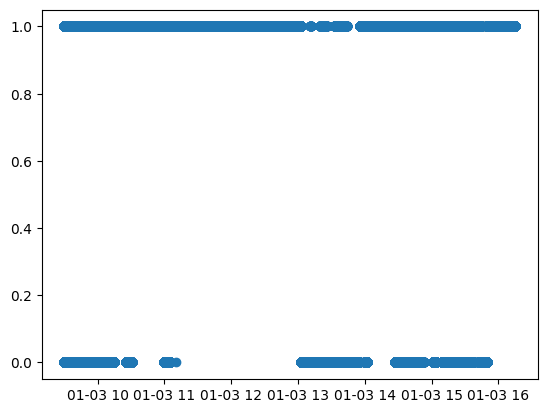

In [75]:
plt.scatter(df_filtered["ts_ns"], np.array(is_arb_iv, dtype=int))

In [76]:
g_2d.shape

(2132958, 21)

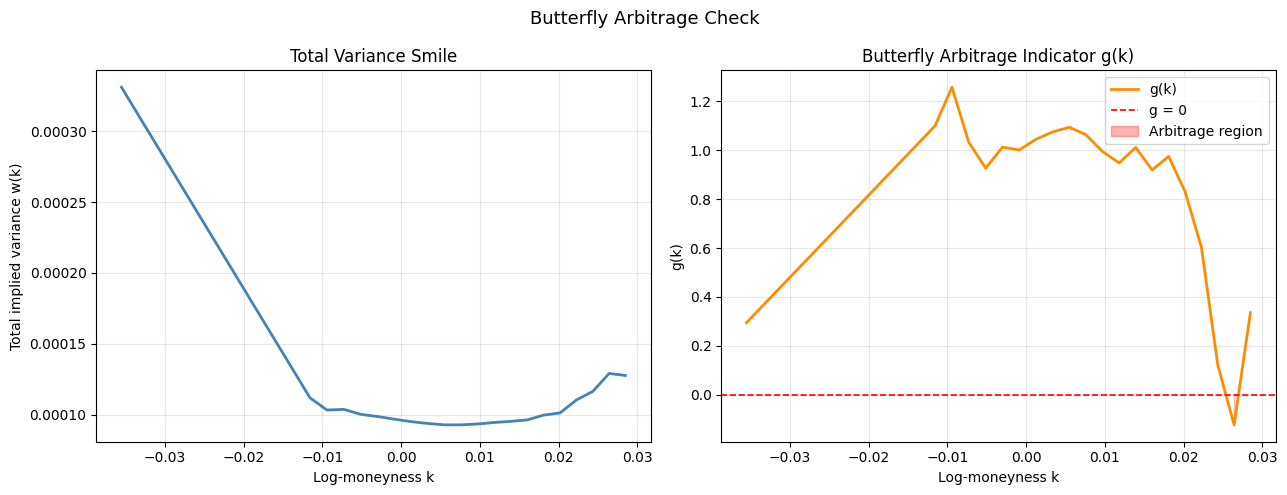

{'is_arbitrage_free': False,
 'min_g': -0.12317745284945236,
 'violations': array([0.02641025]),
 'g': array([ 0.29442694,  1.09950721,  1.25777986,  1.03232629,  0.92687414,
         1.01247633,  1.00099468,  1.04479476,  1.07508104,  1.09396309,
         1.06330602,  0.99442567,  0.94830506,  1.01134555,  0.9194396 ,
         0.97445698,  0.831128  ,  0.6028659 ,  0.12130963, -0.12317745,
         0.33563599]),
 'w': array([3.31260104e-04, 1.11775387e-04, 1.03196427e-04, 1.03641890e-04,
        1.00155090e-04, 9.86087144e-05, 9.67392787e-05, 9.49967875e-05,
        9.37143557e-05, 9.27210082e-05, 9.27221451e-05, 9.33152754e-05,
        9.43974195e-05, 9.51789586e-05, 9.61913817e-05, 9.95987689e-05,
        1.01150730e-04, 1.10310432e-04, 1.16323290e-04, 1.29042967e-04,
        1.27597718e-04]),
 'k': array([-0.0355092 , -0.011569  , -0.00942077, -0.00727714, -0.00513811,
        -0.00300363, -0.00087371,  0.00125169,  0.00337258,  0.00548899,
         0.00760092,  0.0097084 ,  0.0118

In [77]:
i = 1800000
otm_strikes, otm_mid, otm_bid, otm_ask = extract_otm_details(i, df_filtered, strikes_C, strikes_P)
fig = go.Figure()
fig.add_trace(go.Scatter(x=otm_strikes, y=otm_mid, mode="lines+markers", name="OTM kalman mid"))
fig.add_trace(
    go.Scatter(x=otm_strikes, y=otm_bid, mode="lines", name="OTM bid", line=dict(dash="dot"))
)
fig.add_trace(
    go.Scatter(x=otm_strikes, y=otm_ask, mode="lines", name="OTM ask", line=dict(dash="dot"))
)
fig.add_vline(x=spy_mid, line_dash="dash", line_color="gray", annotation_text=f"SPY={spy_mid:.2f}")
fig.update_layout(
    title=f"OTM IV smile — {snapshot_ts}",
    xaxis_title="Strike",
    yaxis_title="Implied Vol",
)
fig.show()
arbitrage.check_butterfly(k=k_2d[i], iv=iv_2d[i], T=tte_arr[i], plot=True)

In [78]:
df_filtered_arb

ts_ns,bid_iv_450_P,ask_iv_450_P,kalman_iv_450_P,bid_iv_454_C,ask_iv_454_C,kalman_iv_454_C,bid_iv_458_P,ask_iv_458_P,kalman_iv_458_P,bid_iv_459_P,ask_iv_459_P,kalman_iv_459_P,bid_iv_460_P,ask_iv_460_P,kalman_iv_460_P,bid_iv_461_P,ask_iv_461_P,kalman_iv_461_P,bid_iv_462_P,ask_iv_462_P,kalman_iv_462_P,bid_iv_462_P_right,ask_iv_462_P_right,kalman_iv_462_P_right,bid_iv_463_P,ask_iv_463_P,kalman_iv_463_P,bid_iv_464_P,ask_iv_464_P,kalman_iv_464_P,bid_iv_465_P,ask_iv_465_P,kalman_iv_465_P,bid_iv_465_C,ask_iv_465_C,kalman_iv_465_C,…,ask_iv_476_C,kalman_iv_476_C,bid_iv_477_P,ask_iv_477_P,kalman_iv_477_P,bid_iv_477_C,ask_iv_477_C,kalman_iv_477_C,bid_iv_478_C,ask_iv_478_C,kalman_iv_478_C,bid_iv_479_C,ask_iv_479_C,kalman_iv_479_C,bid_iv_480_C,ask_iv_480_C,kalman_iv_480_C,bid_iv_481_C,ask_iv_481_C,kalman_iv_481_C,bid_iv_482_C,ask_iv_482_C,kalman_iv_482_C,bid_iv_483_C,ask_iv_483_C,kalman_iv_483_C,bid_iv_484_C,ask_iv_484_C,kalman_iv_484_C,forward,negative_mass_C,negative_mass_P,is_arbitrage_C,is_arbitrage_P,min_g_C,is_arbitrage_iv_C,is_arbitrage_price_C
"datetime[ns, America/New_York]",f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,…,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,bool,bool,f64,bool,bool
2024-01-03 09:30:00.232904704 EST,0.23373,0.254876,0.245507,0.01,0.307464,0.196493,0.176954,0.181464,0.179261,0.169343,0.173275,0.172949,0.164414,0.16761,0.167349,0.156516,0.159098,0.157821,0.152496,0.154547,0.154174,0.151299,0.153178,0.152464,0.149082,0.150786,0.150466,0.147237,0.148611,0.147927,0.143565,0.145845,0.14471,0.143507,0.156301,0.150034,…,0.134238,0.133077,0.143898,0.159937,0.152162,0.136279,0.137805,0.136292,0.136856,0.138807,0.137211,0.13647,0.139103,0.138346,0.139489,0.142976,0.139871,0.14307,0.147414,0.144089,0.139856,0.1458,0.140269,0.145147,0.15349,0.149482,0.154975,0.163817,0.158405,470.745,-5.138446,-5.017202,true,true,-0.008828,true,true
2024-01-03 09:30:00.249509376 EST,0.245502,0.254871,0.246281,0.01,0.307464,0.196493,0.176954,0.181464,0.179261,0.169343,0.173275,0.172949,0.164414,0.16761,0.167349,0.156516,0.159098,0.157821,0.152496,0.154547,0.154174,0.151299,0.153178,0.152464,0.149082,0.150786,0.150466,0.147237,0.148611,0.147927,0.143565,0.145845,0.14471,0.143507,0.156301,0.150034,…,0.134238,0.133077,0.143898,0.159937,0.152162,0.136279,0.137805,0.136292,0.136856,0.138807,0.137211,0.13647,0.139103,0.138346,0.139489,0.142976,0.139871,0.14307,0.147414,0.144089,0.139856,0.1458,0.140269,0.145147,0.15349,0.149482,0.154975,0.163817,0.158405,470.745,-5.138446,-5.017304,true,true,-0.008828,true,true
2024-01-03 09:30:00.326542848 EST,0.245502,0.254871,0.246281,0.01,0.307464,0.196493,0.176954,0.181464,0.179261,0.169343,0.173275,0.172949,0.164414,0.16761,0.167349,0.156516,0.159098,0.157821,0.152496,0.154547,0.154174,0.151299,0.153178,0.152464,0.149082,0.150786,0.150466,0.147237,0.148611,0.147927,0.143565,0.145845,0.14471,0.143507,0.156301,0.150034,…,0.134238,0.133077,0.143898,0.159937,0.152162,0.136279,0.137805,0.136292,0.136856,0.138807,0.137211,0.13647,0.139103,0.138346,0.139489,0.142976,0.139871,0.14307,0.147414,0.144089,0.139856,0.1458,0.140269,0.145147,0.15349,0.149482,0.154975,0.163817,0.158405,470.745,-5.138446,-5.017304,true,true,-0.008828,true,true
2024-01-03 09:30:00.326573312 EST,0.245502,0.254871,0.246281,0.01,0.307464,0.196493,0.176954,0.181464,0.179261,0.169343,0.173275,0.172949,0.164414,0.16761,0.167349,0.156516,0.159098,0.157821,0.152496,0.154547,0.154174,0.151299,0.153178,0.152464,0.149082,0.150786,0.150466,0.147237,0.148611,0.147927,0.143565,0.145845,0.14471,0.143507,0.156301,0.150034,…,0.134238,0.133077,0.143898,0.159937,0.152162,0.136279,0.137805,0.136292,0.136856,0.138807,0.137211,0.13647,0.139103,0.138346,0.128363,0.139425,0.131097,0.14307,0.147414,0.144089,0.139856,0.1458,0.140269,0.145147,0.15349,0.149482,0.154975,0.163817,0.158405,47

In [79]:
df_filtered_arb.filter(pl.col("is_arbitrage_iv_C") == True).select(pl.col("min_g_C")).describe()

statistic,min_g_C
str,f64
"""count""",1.432119e6
"""null_count""",0.0
"""mean""",-0.454943
"""std""",0.581095
"""min""",-23.073984
"""25%""",-0.649681
"""50%""",-0.33297
"""75%""",-0.160433
"""max""",-0.000007


In [80]:
df_filtered_arb.select(pl.col("is_arbitrage_iv_C") == True)

is_arbitrage_iv_C
bool
true
true
true
true
true
…
true
true
true


In [81]:
# to be tested

In [82]:
# run over all rows, see how many disagree/agree.

In [83]:
strikesx

array([0.76591671, 0.95739588, 0.96590607, 0.97441625, 0.9765438 ,
       0.97867135, 0.98079889, 0.98292644, 0.98399021, 0.98505399,
       0.98718153, 0.98930908, 0.99143663, 0.99356417, 0.99569172,
       0.99781926, 0.99994681, 1.00207436, 1.0042019 , 1.00632945,
       1.008457  , 1.01058454, 1.01271209, 1.01483964, 1.01696718,
       1.01909473, 1.02122228, 1.02334982, 1.02547737, 1.02760491,
       1.02973246, 1.23567895])

In [84]:
ratio, total

(np.float64(-0.054108196688374376), np.float64(1.0))

archive


In [85]:
# has_C_set = {k for k in otm_strikes if f"kalman_iv_{int(k)}_C" in df_filtered.columns}
# has_P_set = {k for k in otm_strikes if f"kalman_iv_{int(k)}_P" in df_filtered.columns}

# for i in range(0, df_filtered.shape[0], 100):
#     row = df_filtered[i]
#     ts = row["ts_ns"][0]
#     tte = float((expiry - ts).total_seconds()) / (365.25 * 24 * 3600)
#     spy_mid = df_spy.filter(pl.col("ts_ns") <= ts)["price"][-1]

#     valid_strikes, valid_ivs = [], []
#     for k in otm_strikes:
#         K_int = int(k)
#         has_C = k in has_C_set
#         has_P = k in has_P_set

#         if has_C and has_P:
#             bid_C, ask_C = row[f"bid_iv_{K_int}_C"][0], row[f"ask_iv_{K_int}_C"][0]
#             bid_P, ask_P = row[f"bid_iv_{K_int}_P"][0], row[f"ask_iv_{K_int}_P"][0]
#             i_bid, i_ask = max(bid_C, bid_P), min(ask_C, ask_P)
#             iv = (
#                 (i_bid + i_ask) / 2
#                 if i_bid <= i_ask
#                 else (
#                     row[f"kalman_iv_{K_int}_C"][0]
#                     if k > spy_mid
#                     else row[f"kalman_iv_{K_int}_P"][0]
#                 )
#             )
#         elif has_C:
#             iv = row[f"kalman_iv_{K_int}_C"][0]
#         elif has_P:
#             iv = row[f"kalman_iv_{K_int}_P"][0]
#         else:
#             continue

#         valid_strikes.append(k)
#         valid_ivs.append(iv)

#     if not arbitrage.check_butterfly(k=valid_strikes, iv=valid_ivs, T=tte, plot=False)[
#         "is_arbitrage_free"
#     ]:
#         print(f"Arbitrage detected at index {i} (timestamp {ts})")